# SCORE-Net: Manuscript Figure Generation

This notebook generates all high-resolution vector (**PDF**) and publication-quality raster (**PNG**) figures used in **Section 4: Experiments and Results** of the SCORE-Net manuscript and saves them directly to `paper/neurocomputing/figures/`.

> **Numbering:** Local figure labels 1-5 in this notebook correspond to Figures 4, 6, 8, 9, and 10 in the manuscript.

### All numbers are read from training artifacts

No accuracy, rule count, feature index, or checkpoint path is hard-coded. Inputs:

* `models/<dataset>/training_history.json` - **validation** accuracy and sparsity for each pruning iteration.
* `models/<dataset>/global-best-weights.pth` and `final-iter-best-weights.pth` - trained checkpoints.
* `results/baselines_*.csv` - comparison results saved by the baseline notebooks.

### Generated figures

1. **`fig_pruning_trajectory.pdf`** - IMP pruning trajectories (validation accuracy vs. sparsity).
2. **`fig_scorecard_dashboard.pdf`** - scorecard quantization panel (global scale sensitivity, integer point span, and per-rule adaptive $\lambda_h$).
3. **`fig_local_feature_curves.pdf`** - continuous piecewise-linear local feature response curves with analytic breakpoints.
4. **`fig_actionable_recourse.pdf`** - analytic actionable recourse via exact linear root finding.
5. **`fig_feature_interaction.pdf`** - architectural feature co-occurrence and Jaccard similarity heatmap.

> **Run order:** all training notebooks first, then `notebooks/01_baselines.ipynb`, and this notebook last. See `README.md` for details.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project root regardless of the notebook's working directory.
cwd = Path.cwd().resolve()
project_root = next(
    (path for path in [cwd, *cwd.parents] if (path / "utils" / "experiments.py").exists()),
    cwd.parent,
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.reproducibility import set_seed
from utils.analysis import (
    calculate_feature_rule_cooccurrence,
    evaluate_scorecard_quantization_analysis,
)
from utils.experiments import (
    DATASETS,
    FIGURE_DIR,
    load_compact_model,
    load_history,
    load_splits,
    save_figure,
)
from utils.plot_utils import plot_exact_actionable_recourse
from utils.rules import response_breakpoints

set_seed(42)

output_fig_dir = FIGURE_DIR
output_fig_dir.mkdir(parents=True, exist_ok=True)

# Academic publication plot styles (IEEE-compatible).
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "figure.titlesize": 14,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

print(f"Project root   : {project_root}")
print(f"Figure output dir: {output_fig_dir}")
print(f"PyTorch version: {torch.__version__}")

Project root   : /home/ahmet/Projects/ScoreNetSingle
Figure output dir: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures
PyTorch version: 2.6.0+cu124


[Data] Loading German Credit Risk...


-> German Credit ready: train shape: (800, 48), Test Shape: (100, 48), feature count: 48, Val Shape: (100, 48)
[Data] Loading UCI Adult Census Income...


-> UCI Adult ready: train shape: (32559, 97), Test Shape: (9045, 97), feature count: 97, Val Shape: (3618, 97)


findfont: Failed to find font weight semibold, now using 700.


Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_pruning_trajectory.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_pruning_trajectory.png


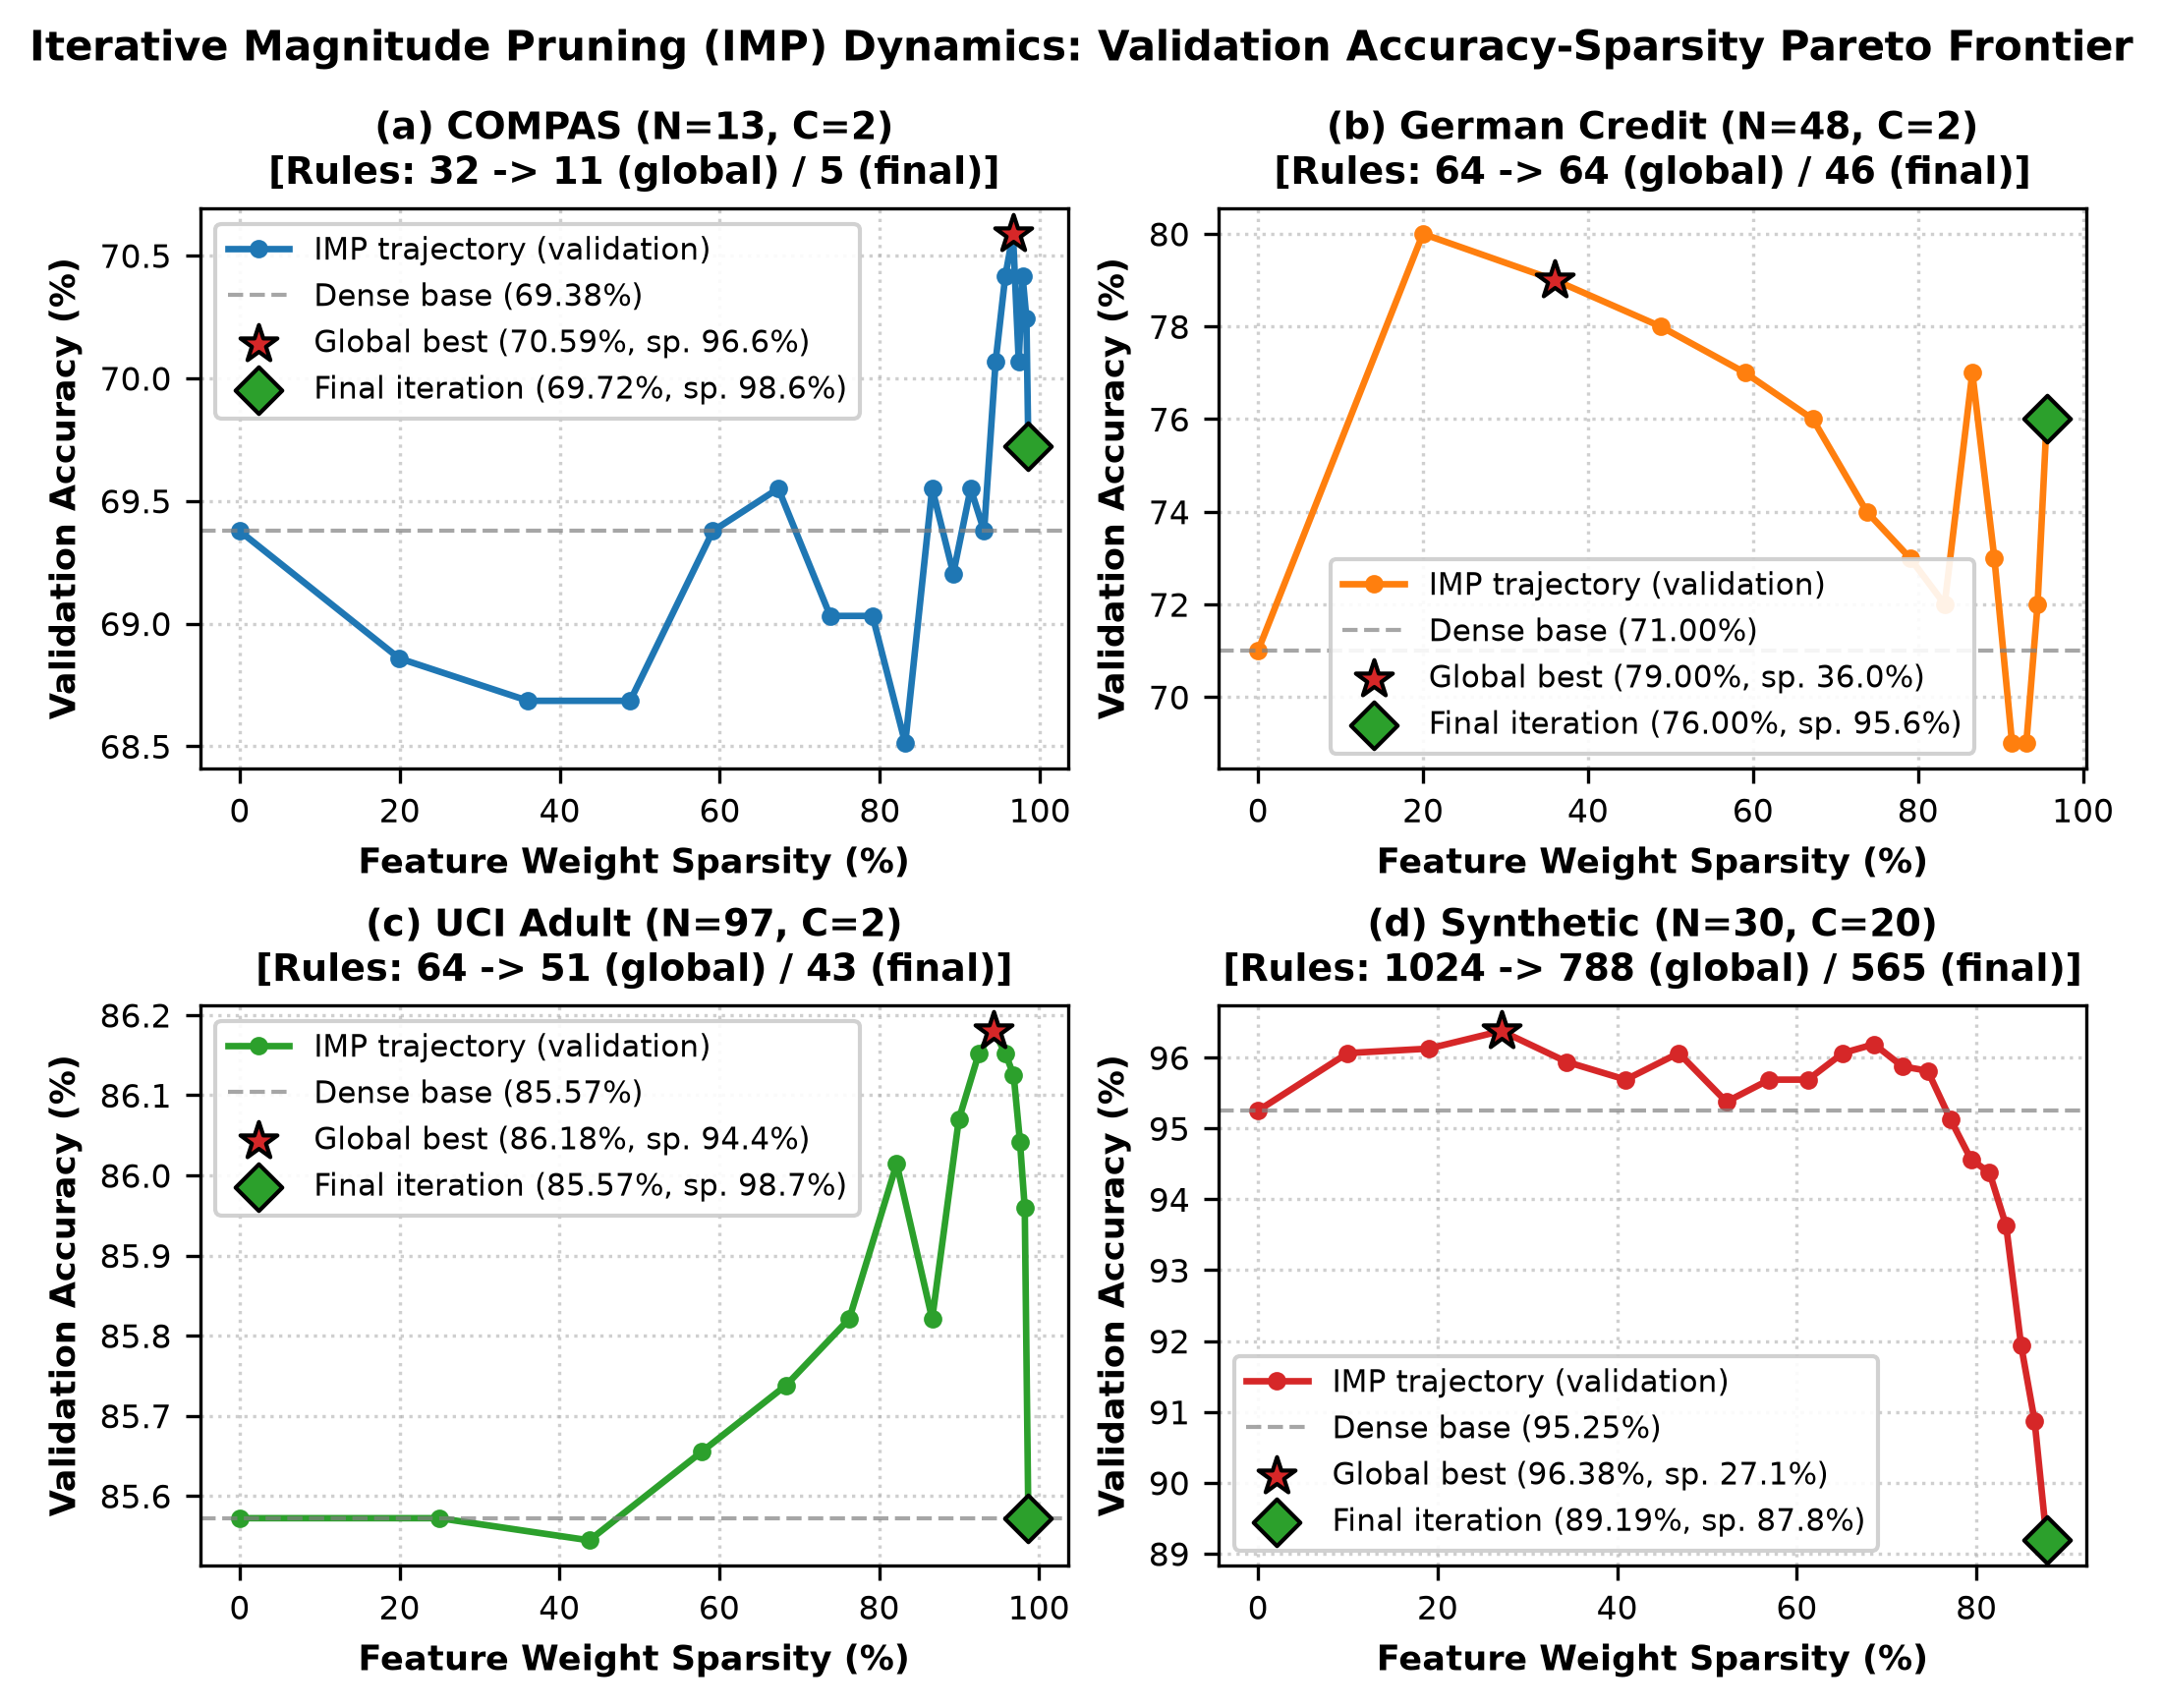


Summary:
      Dataset  H_init  Global rules  Final rules  Best iteration  Best val acc (%)  Final val acc (%)
       COMPAS      32            11            5              15             70.59              69.72
German Credit      64            64           46               2             79.00              76.00
    UCI Adult      64            51           43              10             86.18              85.57
    Synthetic    1024           788          565               3             96.38              89.19


In [2]:
# ==============================================================================
# FIGURE 1: IMP PRUNING TRAJECTORIES (VALIDATION ACCURACY vs. SPARSITY)
# ==============================================================================
# The curve is read from training_history.json written by the training notebook.
# The recorded accuracy is validation accuracy; the test set is not used in this figure.
# Rendered at text width with >= 7 pt type at print size.

fig, axes = plt.subplots(2, 2, figsize=(7.16, 5.7))
axes = axes.flatten()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
summary_rows = []

for idx, key in enumerate(["compas", "german", "adult", "synthetic"]):
    spec = DATASETS[key]
    split = load_splits(key)
    history = load_history(key)

    iterations = history["iterations"]
    sparsity = np.array([it["feature_sparsity_pct"] for it in iterations], dtype=float)
    accuracy = np.array([it["val_accuracy"] for it in iterations], dtype=float) * 100.0

    best_iteration = int(history.get("global_best_iteration", int(np.argmax(accuracy))))
    best_idx = next(
        (i for i, it in enumerate(iterations) if int(it["iteration"]) == best_iteration),
        int(np.argmax(accuracy)),
    )
    final_idx = len(iterations) - 1

    train_loader = split.loader("train")
    global_model = load_compact_model(spec.global_checkpoint, train_loader)
    final_model = load_compact_model(spec.final_checkpoint, train_loader)

    ax = axes[idx]
    ax.plot(
        sparsity, accuracy, color=colors[idx], marker="o", markersize=3.5,
        linewidth=1.6, label="IMP trajectory (validation)",
    )
    ax.axhline(
        accuracy[0], color="gray", linestyle="--", linewidth=1.0, alpha=0.7,
        label=f"Dense base ({accuracy[0]:.2f}%)",
    )
    ax.scatter(
        sparsity[best_idx], accuracy[best_idx], color="#d62728", s=90,
        zorder=5, edgecolors="black", marker="*",
        label=f"Global best ({accuracy[best_idx]:.2f}%, sp. {sparsity[best_idx]:.1f}%)",
    )
    ax.scatter(
        sparsity[final_idx], accuracy[final_idx], color="#2ca02c", s=65,
        zorder=5, edgecolors="black", marker="D",
        label=f"Final iteration ({accuracy[final_idx]:.2f}%, sp. {sparsity[final_idx]:.1f}%)",
    )

    ax.set_title(
        f"({chr(97 + idx)}) {spec.display_name} (N={split.n_features}, C={split.n_classes})\n"
        f"[Rules: {history['H_init']} -> {global_model.H} (global) / {final_model.H} (final)]",
        fontweight="bold", fontsize=9.0,
    )
    ax.set_xlabel("Feature Weight Sparsity (%)", fontweight="semibold", fontsize=8.5)
    ax.set_ylabel("Validation Accuracy (%)", fontweight="semibold", fontsize=8.5)
    ax.tick_params(labelsize=8.0)
    ax.grid(True, linestyle=":", alpha=0.6)

    # The German Credit curve fills the upper half of the panel, so even "best"
    # would cover it; the lower-center area is empty there.
    legend_loc = "lower center" if key == "german" else "best"
    ax.legend(loc=legend_loc, frameon=True, framealpha=0.9, fontsize=7.5)

    summary_rows.append({
        "Dataset": spec.display_name,
        "H_init": history["H_init"],
        "Global rules": global_model.H,
        "Final rules": final_model.H,
        "Best iteration": best_iteration,
        "Best val acc (%)": round(float(accuracy[best_idx]), 2),
        "Final val acc (%)": round(float(accuracy[final_idx]), 2),
    })

plt.suptitle(
    "Iterative Magnitude Pruning (IMP) Dynamics: Validation Accuracy-Sparsity Pareto Frontier",
    fontweight="bold", fontsize=10.0, y=0.995,
)
plt.tight_layout(pad=0.5)
save_figure(fig, "fig_pruning_trajectory")
plt.show()

print("\nSummary:")
print(pd.DataFrame(summary_rows).to_string(index=False))

[Data] Loading German Credit Risk...
-> German Credit ready: train shape: (800, 48), Test Shape: (100, 48), feature count: 48, Val Shape: (100, 48)


Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_scorecard_dashboard.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_scorecard_dashboard.png


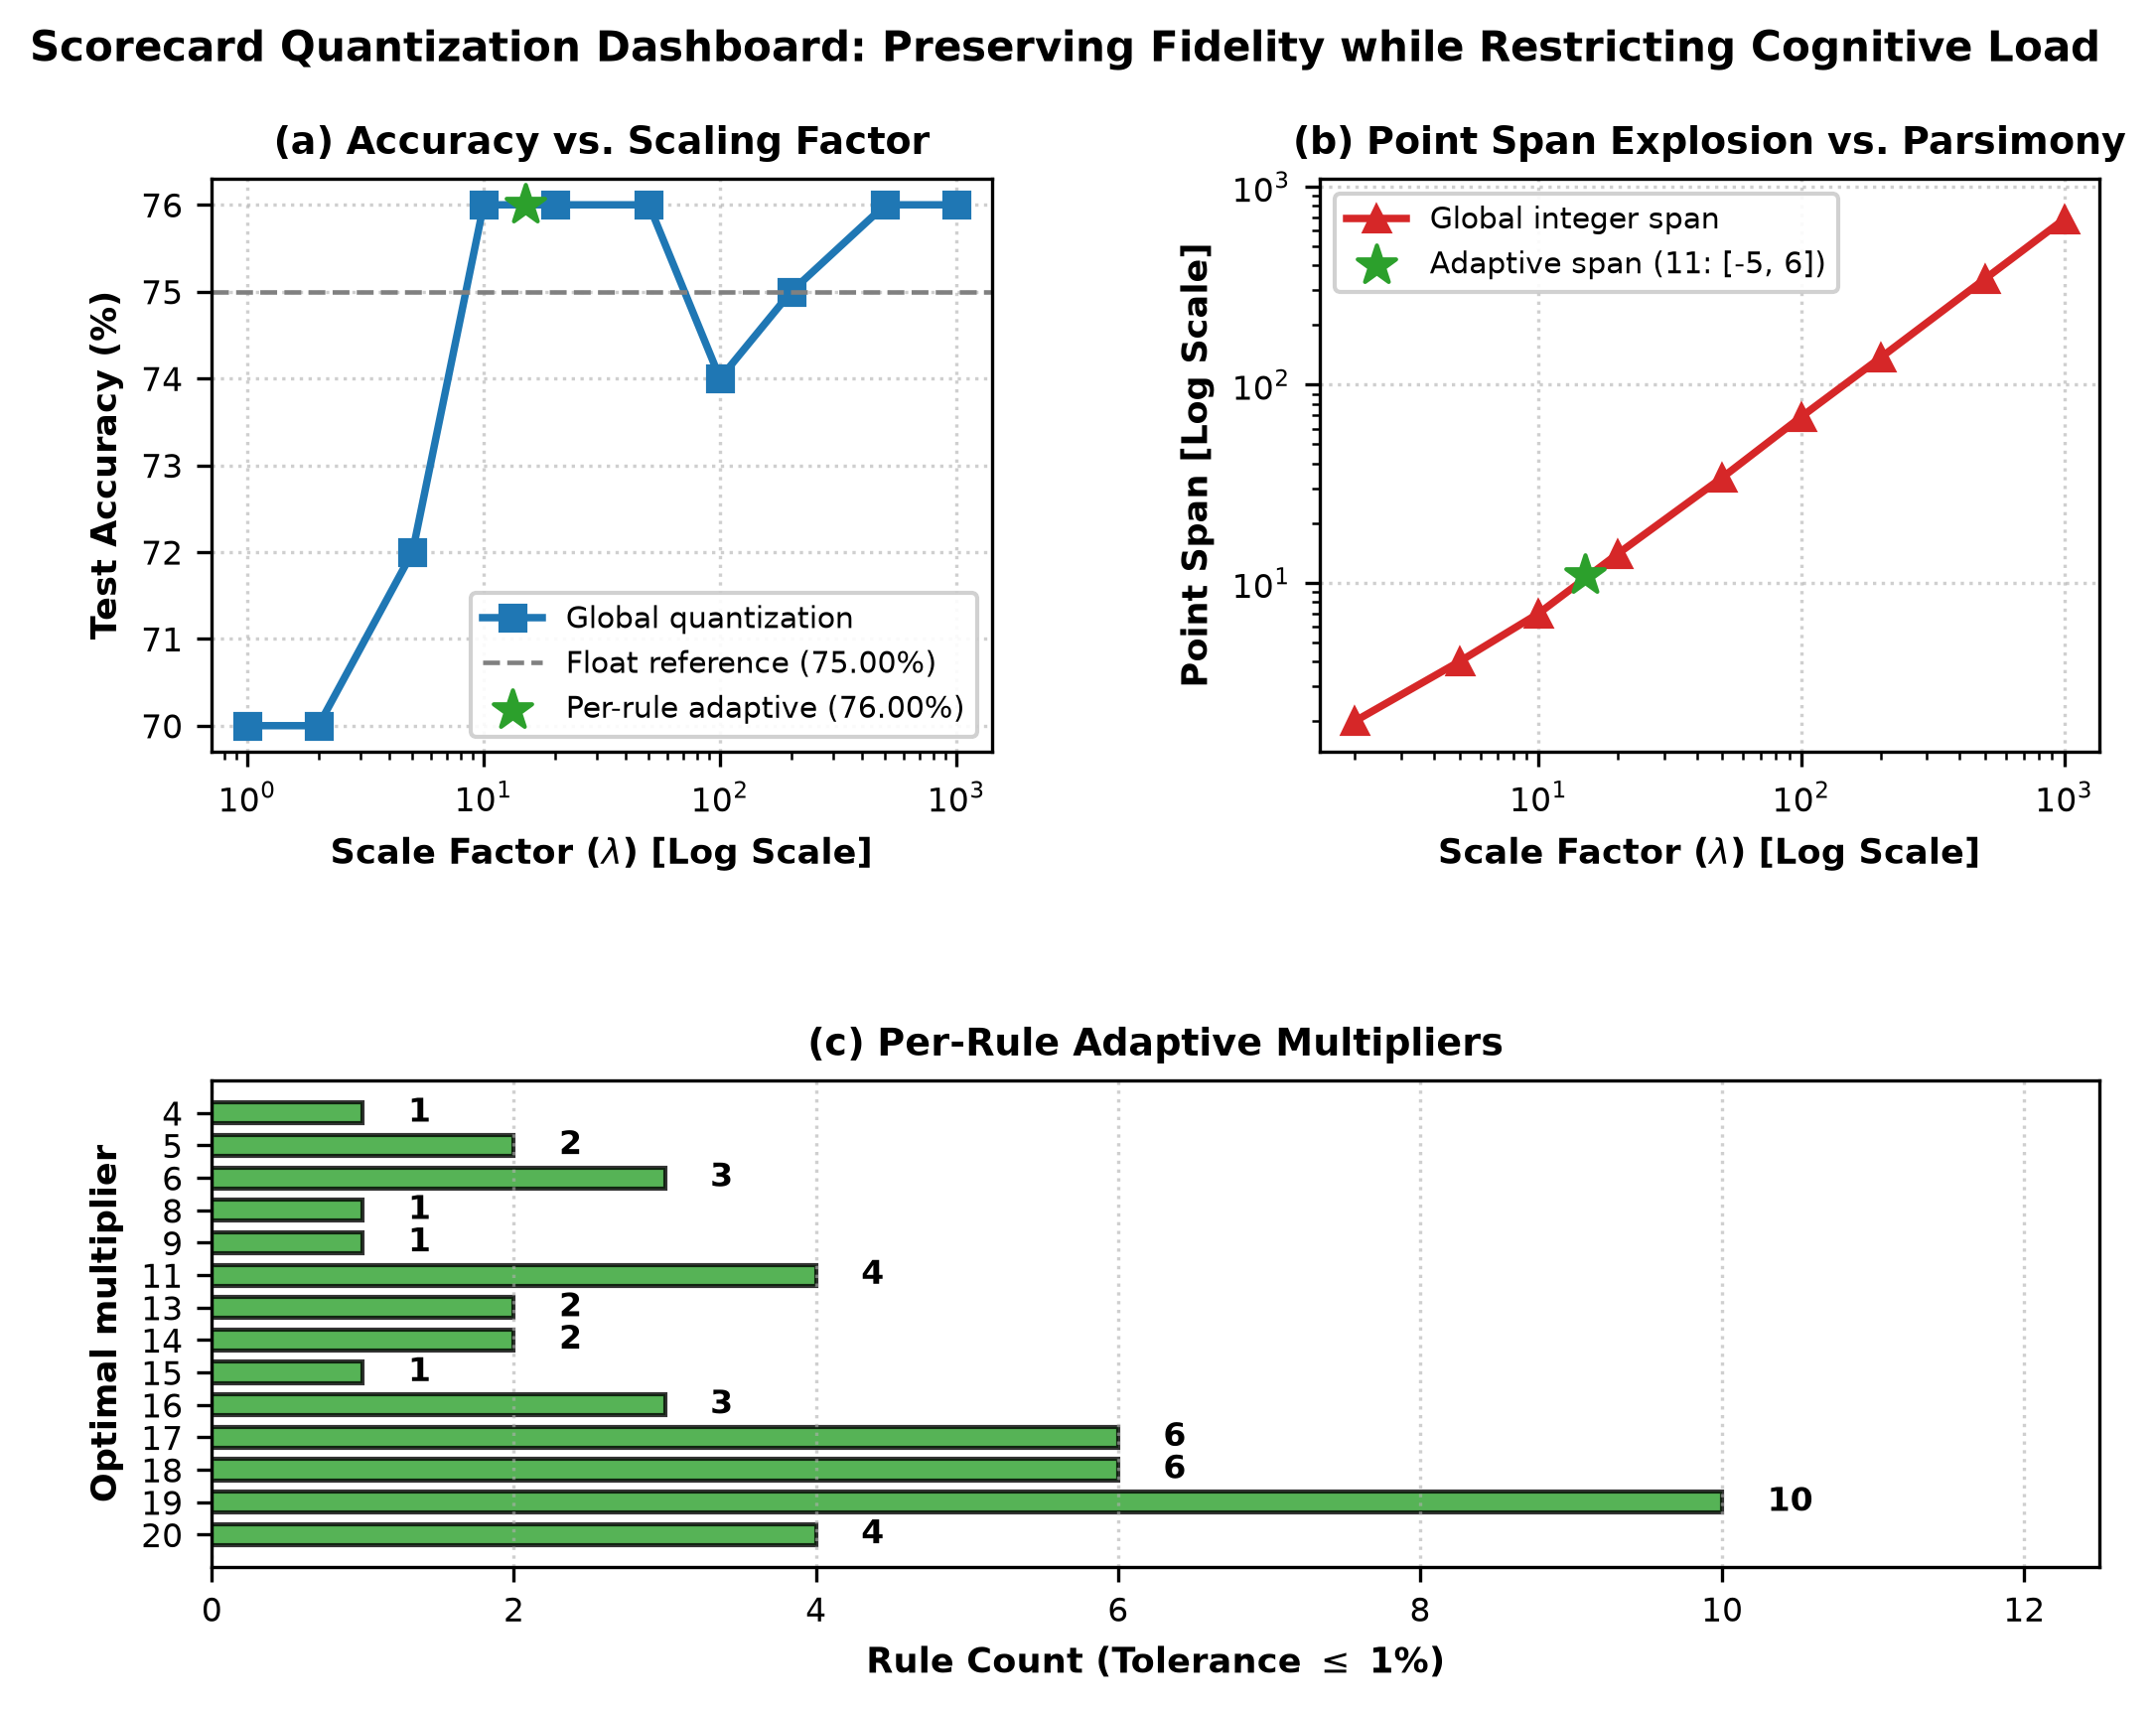


Quantization summary:
                          Method  Accuracy (%)  Accuracy Loss (%)  Mean Scale (λ) Min Integer Score Max Integer Score  Mean Weight Magnitude  Fidelity (%)  Max Logit Drift
            Original Float Model          75.0                0.0             1.0               N/A               N/A               0.010652    100.000000         0.000000
Rule-Based Adaptive Quantization          76.0               -1.0            15.0                -5                 6               0.167572     97.000003         0.325345

Mean lambda per rule: 15.00


In [3]:
# ==============================================================================
# FIGURE 2: SCORECARD QUANTIZATION AND FIDELITY PANEL (GERMAN CREDIT)
# ==============================================================================
# The quantization budget comes from a single source (German Credit, compact model).
# Rendered at text width with >= 7 pt type at print size.
BUDGET = DATASETS["german"].quantization("Compact")

split_gc = load_splits("german")
train_loader_gc = split_gc.loader("train")
test_loader_gc = split_gc.loader("test", batch_size=256)
model_gc = load_compact_model(DATASETS["german"].final_checkpoint, train_loader_gc)

df_global, df_adaptive, df_rule_scales = evaluate_scorecard_quantization_analysis(
    model_gc,
    test_loader_gc,
    tolerance_error=BUDGET.tolerance,
    max_adaptive_scale=BUDGET.max_scale,
)

float_row = df_global[df_global["Scale_Factor"] == "Float (Original)"].iloc[0]
global_rows = df_global[df_global["Scale_Factor"] != "Float (Original)"].copy()
global_rows["lambda"] = global_rows["Scale_Factor"].astype(float)
global_rows["acc_pct"] = global_rows["Accuracy"] * 100.0
global_rows["span"] = pd.to_numeric(global_rows["Max_Int_Span"])
float_ref_acc = float(float_row["Accuracy"]) * 100.0

adaptive_row = df_adaptive[df_adaptive["Method"].str.contains("Adaptive")].iloc[0]
adaptive_acc = float(adaptive_row["Accuracy (%)"])
adaptive_scale = float(adaptive_row["Mean Scale (λ)"])
adaptive_min = int(adaptive_row["Min Integer Score"])
adaptive_max = int(adaptive_row["Max Integer Score"])
adaptive_span = adaptive_max - adaptive_min
rule_lambdas = df_rule_scales["Optimal_Scale_Factor"].to_numpy()

fig = plt.figure(figsize=(7.16, 5.9), dpi=300)
gs = fig.add_gridspec(
    2, 2, height_ratios=[1.0, 0.85], hspace=0.62, wspace=0.42,
    left=0.10, right=0.985, top=0.90, bottom=0.11,
)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

# (a) Accuracy vs. scale
ax1.plot(
    global_rows["lambda"], global_rows["acc_pct"], marker="s",
    color="#1f77b4", linewidth=1.8, label="Global quantization",
)
ax1.axhline(
    float_ref_acc, color="gray", linestyle="--", linewidth=1.1,
    label=f"Float reference ({float_ref_acc:.2f}%)",
)
ax1.scatter(
    [adaptive_scale], [adaptive_acc], color="#2ca02c", s=95, zorder=5,
    marker="*", label=f"Per-rule adaptive ({adaptive_acc:.2f}%)",
)
ax1.set_xscale("log")
ax1.set_xlabel(r"Scale Factor ($\lambda$) [Log Scale]", fontweight="bold", fontsize=8.5)
ax1.set_ylabel("Test Accuracy (%)", fontweight="bold", fontsize=8.5)
ax1.set_title("(a) Accuracy vs. Scaling Factor", fontweight="bold", fontsize=9.0)
ax1.tick_params(labelsize=8.0)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", frameon=True, framealpha=0.9, fontsize=7.2)

# (b) Integer point span
span_rows = global_rows[global_rows["span"] > 0]
ax2.plot(
    span_rows["lambda"], span_rows["span"], marker="^", color="#d62728",
    linewidth=1.8, label="Global integer span",
)
if adaptive_span > 0:
    ax2.scatter(
        [adaptive_scale], [adaptive_span], color="#2ca02c", s=95,
        zorder=5, marker="*",
        label=f"Adaptive span ({adaptive_span}: [{adaptive_min}, {adaptive_max}])",
    )
ax2.set_xscale("log")
ax2.set_yscale("log")
positive_spans = list(span_rows["span"]) + ([adaptive_span] if adaptive_span > 0 else [])
if positive_spans:
    ax2.set_ylim(max(1.0, min(positive_spans) * 0.7), max(positive_spans) * 1.6)
ax2.set_xlabel(r"Scale Factor ($\lambda$) [Log Scale]", fontweight="bold", fontsize=8.5)
ax2.set_ylabel("Point Span [Log Scale]", fontweight="bold", fontsize=8.5)
ax2.set_title("(b) Point Span Explosion vs. Parsimony", fontweight="bold", fontsize=9.0)
ax2.tick_params(labelsize=8.0)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left", frameon=True, framealpha=0.9, fontsize=7.2)

# (c) Distribution of the lambda selected per rule (horizontal bars: labels do
# not overlap when there are many distinct lambda values).
values, counts = np.unique(rule_lambdas, return_counts=True)
y_lambda = np.arange(len(values))
ax3.barh(
    y_lambda, counts, color="#2ca02c", edgecolor="black", alpha=0.8, height=0.65,
)
for y, count in zip(y_lambda, counts):
    ax3.text(
        count + max(0.12, 0.03 * max(counts)), y, f"{int(count)}",
        ha="left", va="center", fontsize=8.0, fontweight="bold",
    )
ax3.set_yticks(y_lambda)
ax3.set_yticklabels([f"{int(v)}" for v in values], fontsize=8.0)
ax3.invert_yaxis()
ax3.set_xlim(0, max(counts) + max(2.0, 0.25 * max(counts)))
ax3.set_xlabel(
    r"Rule Count (Tolerance $\leq$ " + f"{BUDGET.tolerance * 100:.0f}" + r"%)",
    fontweight="bold", fontsize=8.5,
)
ax3.set_ylabel("Optimal multiplier", fontweight="bold", fontsize=8.5)
ax3.set_title("(c) Per-Rule Adaptive Multipliers", fontweight="bold", fontsize=9.0)
ax3.tick_params(labelsize=8.0)
ax3.grid(axis="x", linestyle=":", alpha=0.6)

fig.suptitle(
    "Scorecard Quantization Dashboard: Preserving Fidelity while Restricting Cognitive Load",
    fontweight="bold", fontsize=10.0, y=0.985,
)
save_figure(fig, "fig_scorecard_dashboard")
plt.show()

print("\nQuantization summary:")
print(df_adaptive.to_string(index=False))
print(f"\nMean lambda per rule: {rule_lambdas.mean():.2f}")

[Data] Loading German Credit Risk...
-> German Credit ready: train shape: (800, 48), Test Shape: (100, 48), feature count: 48, Val Shape: (100, 48)
Selected applicant index: 67
Applicant logit margin: -0.542
Single-feature actions found: 21


Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_local_feature_curves.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_local_feature_curves.png


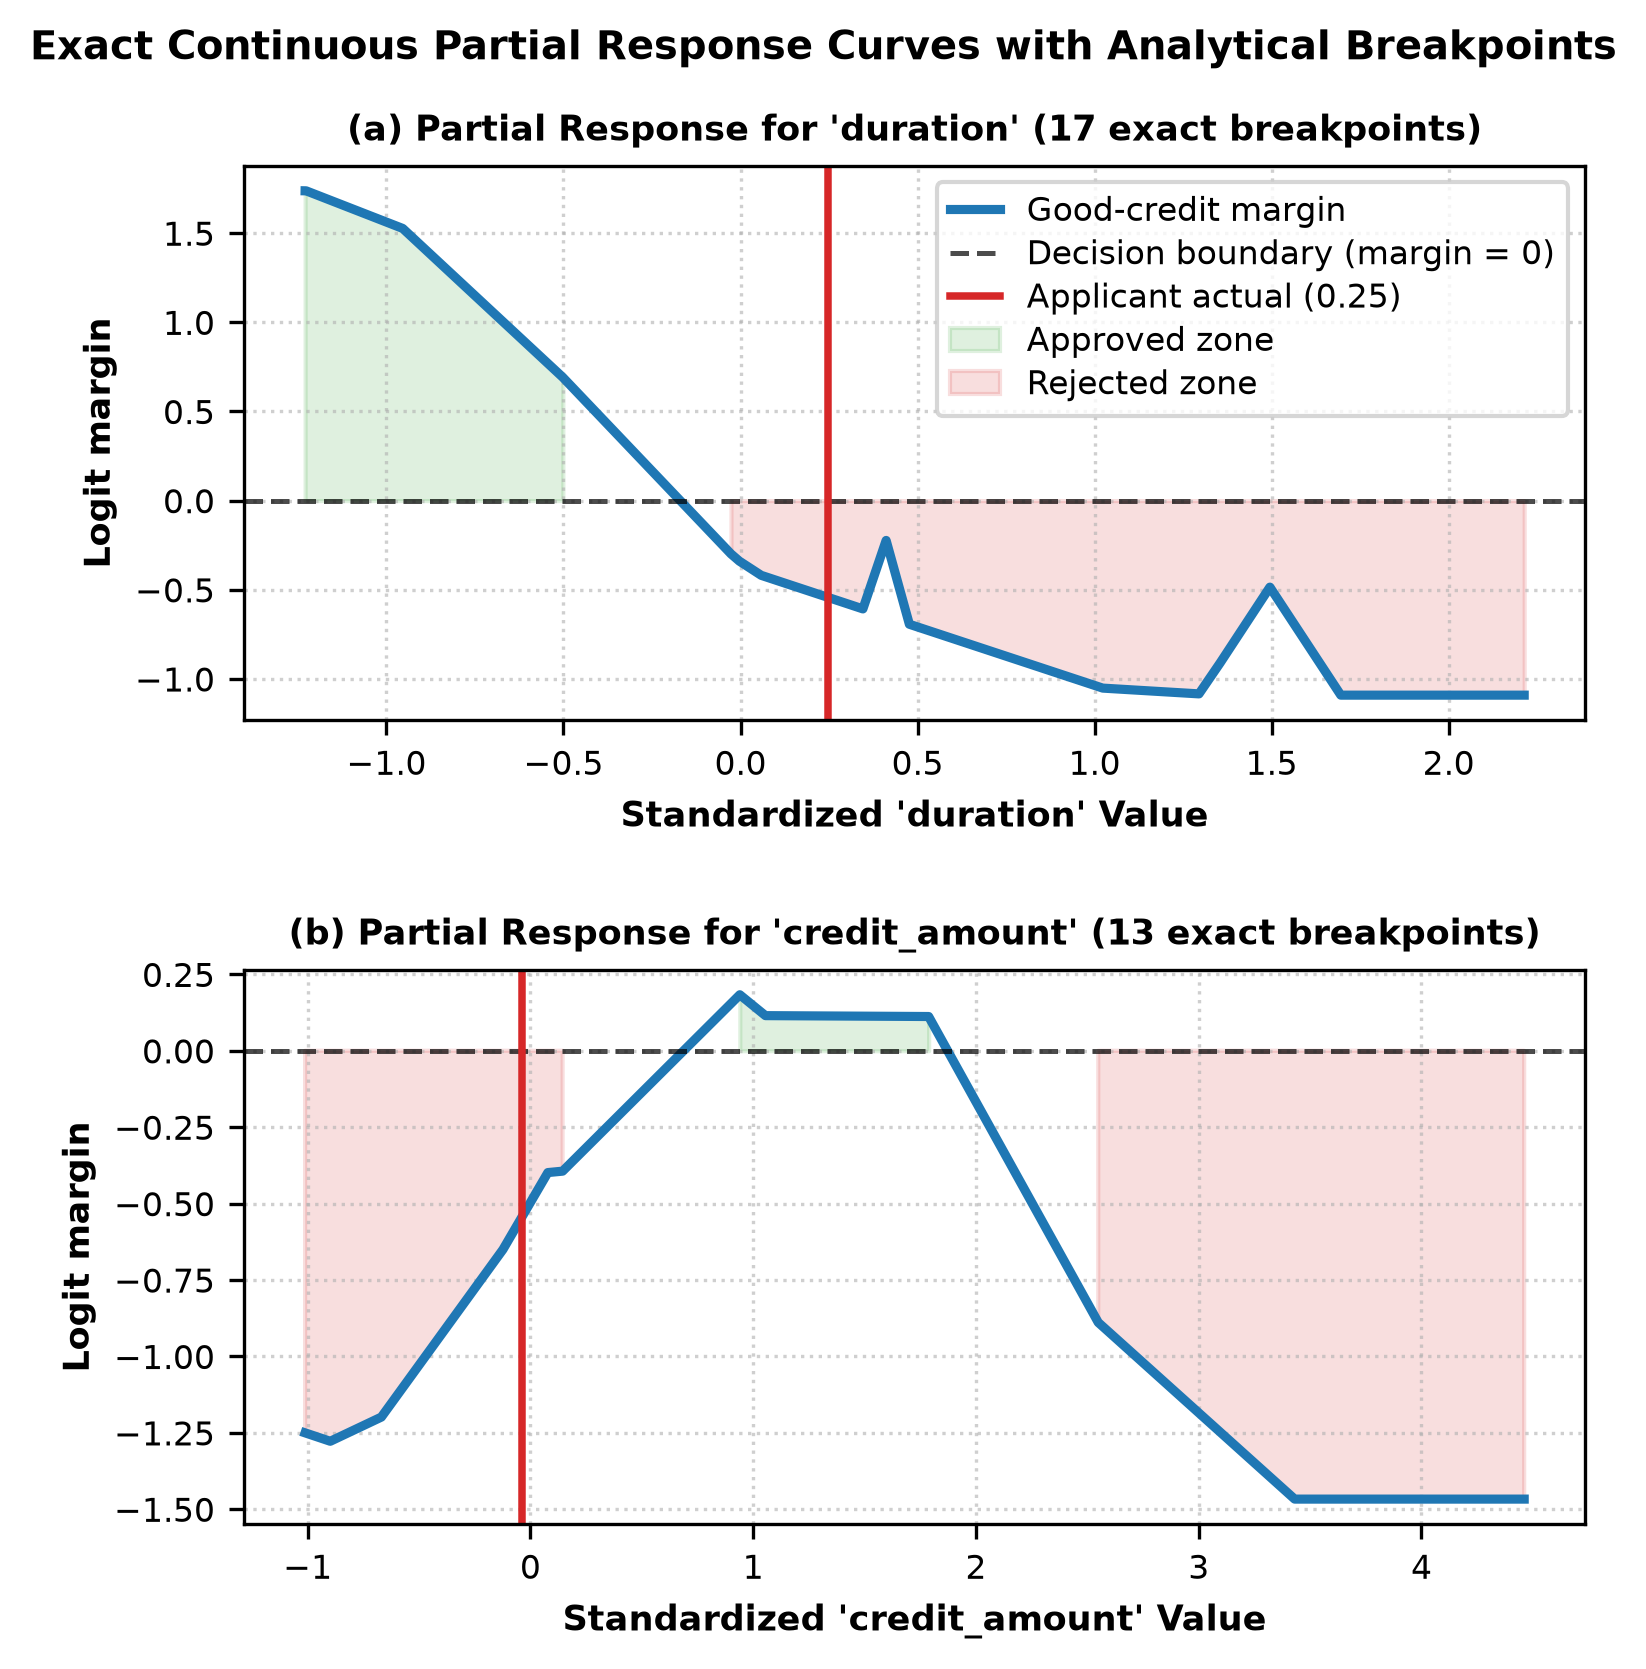

In [4]:
# ==============================================================================
# FIGURE 3: CONTINUOUS PIECEWISE-LINEAR LOCAL FEATURE RESPONSE CURVES
# ==============================================================================
split_gc = load_splits("german")
train_loader_gc = split_gc.loader("train")
model_gc = load_compact_model(DATASETS["german"].final_checkpoint, train_loader_gc)
feature_names_gc = split_gc.feature_names
X_train_gc, X_test_gc = split_gc.X_train, split_gc.X_test

with torch.no_grad():
    logits_all = model_gc(X_test_gc)
    margins_all = logits_all[:, 1] - logits_all[:, 0]
    preds_all = logits_all.argmax(dim=1)

# Among rejected applicants (class 0), select the one closest to the median
# decision margin of rejected cases. This avoids showing a case at the decision
# boundary (margin ~ 0) or at an extreme: a typical rejection is shown.
# Age, marital status/gender, and citizenship are treated as immutable; no
# recourse action is generated for them (immutable_features).
IMMUTABLE_FEATURES = ["age", "personal_status", "foreign_worker"]
rejected = torch.where(preds_all == 0)[0]
if len(rejected) > 0:
    rejected_sorted = rejected[torch.argsort(margins_all[rejected])]
    median_margin = margins_all[rejected_sorted[len(rejected_sorted) // 2]]
    candidate_order = rejected_sorted[
        torch.argsort((margins_all[rejected_sorted] - median_margin).abs())
    ].tolist()
else:
    candidate_order = torch.argsort(margins_all.abs()).tolist()

dataset_mins = X_train_gc.min(dim=0)[0]
dataset_maxs = X_train_gc.max(dim=0)[0]


def _probe_recourse(index):
    # Silently tries single-feature analytic recourse actions for one record.
    import contextlib
    import io

    with contextlib.redirect_stdout(io.StringIO()):
        actions = plot_exact_actionable_recourse(
            model=model_gc,
            single_record=X_test_gc[index],
            dataset_mins=dataset_mins,
            dataset_maxs=dataset_maxs,
            target_class=1,
            feature_names=feature_names_gc,
            top_k=8,
            show_plot=False,
            return_actions=True,
            lang="en",
            immutable_features=IMMUTABLE_FEATURES,
        )
    return actions


selected_idx = None
selected_actions = []
for index in candidate_order:
    actions = _probe_recourse(int(index))
    # Require at least 5 independent actions and an intervention of at least 0.2
    # standard deviations for a meaningful plot.
    if actions and len(actions) >= 5 and max(a["abs_diff"] for a in actions) >= 0.2:
        selected_idx = int(index)
        selected_actions = actions
        break

if selected_idx is None:
    selected_idx = int(candidate_order[0])
    print("Warning: no single-feature recourse was found for any rejected applicant.")

selected_record = X_test_gc[selected_idx]
print(f"Selected applicant index: {selected_idx}")
print(f"Applicant logit margin: {float(margins_all[selected_idx]):+.3f}")
print(f"Single-feature actions found: {len(selected_actions)}")

# Pick two continuous features from a preference list, otherwise by test variance.
preferred_tokens = ["duration", "credit_amount", "amount", "age"]
lower_names = {name.lower(): j for j, name in enumerate(feature_names_gc)}
feat_indices = []
for token in preferred_tokens:
    for lower_name, j in lower_names.items():
        if token in lower_name and j not in feat_indices:
            feat_indices.append(j)
            break
    if len(feat_indices) == 2:
        break
if len(feat_indices) < 2:
    variances = X_test_gc.var(dim=0)
    for j in torch.argsort(variances, descending=True).tolist():
        if j not in feat_indices:
            feat_indices.append(j)
        if len(feat_indices) == 2:
            break
feat_indices = feat_indices[:2]

x_sample = selected_record.unsqueeze(0)
fig, axes = plt.subplots(
    len(feat_indices), 1, figsize=(5.2, 2.7 * len(feat_indices)), squeeze=False
)
axes = axes.flatten()

for i, f_idx in enumerate(feat_indices):
    ax = axes[i]
    fname = feature_names_gc[f_idx]
    orig_val = float(selected_record[f_idx])

    # The curve is evaluated exactly at the breakpoints, NOT on a uniform grid
    # (paper, Equation eq:breakpoints). The logit response is exactly affine
    # between consecutive points, so this leaves no interpolation error, and the
    # number of forward passes depends on the rule count, not the grid size.
    W_col = model_gc.feature_linear.weight.detach()[:, f_idx]
    offset = (model_gc.feature_linear.weight.detach() @ selected_record) - W_col * selected_record[f_idx]
    grid = response_breakpoints(
        W_col,
        model_gc.base_feature_center.detach(),
        model_gc.base_feature_width.detach(),
        offset,
        lower=float(X_test_gc[:, f_idx].min()),
        upper=float(X_test_gc[:, f_idx].max()),
        extra=[orig_val],
    )
    x_pert = x_sample.repeat(len(grid), 1)
    x_pert[:, f_idx] = grid

    with torch.no_grad():
        logits = model_gc(x_pert)
        margin = (logits[:, 1] - logits[:, 0]).cpu().numpy()

    grid_np = grid.cpu().numpy()
    n_points = len(grid_np)
    ax.plot(
        grid_np, margin, color="#1f77b4", linewidth=2.2,
        label="Good-credit margin",
    )
    ax.axhline(
        0, color="black", linestyle="--", linewidth=1.2, alpha=0.7,
        label="Decision boundary (margin = 0)",
    )
    ax.axvline(
        orig_val, color="#d62728", linestyle="-", linewidth=1.8,
        label=f"Applicant actual ({orig_val:.2f})",
    )
    ax.fill_between(
        grid_np, margin, 0, where=(margin >= 0), color="#2ca02c",
        alpha=0.15, label="Approved zone",
    )
    ax.fill_between(
        grid_np, margin, 0, where=(margin < 0), color="#d62728",
        alpha=0.15, label="Rejected zone",
    )
    ax.set_title(
        f"({chr(97 + i)}) Partial Response for '{fname}' "
        f"({n_points} exact breakpoints)",
        fontweight="bold", fontsize=8.5, pad=6,
    )
    ax.set_xlabel(f"Standardized '{fname}' Value", fontweight="semibold", fontsize=8.5)
    ax.set_ylabel("Logit margin", fontweight="semibold", fontsize=8.5)
    ax.tick_params(labelsize=8.0)
    ax.grid(True, linestyle=":", alpha=0.6)
    if i == 0:
        ax.legend(
            loc="upper right", frameon=True, fontsize=8.0,
            handlelength=1.5, labelspacing=0.3, borderpad=0.4,
        )

plt.suptitle(
    "Exact Continuous Partial Response Curves with Analytical Breakpoints",
    fontweight="bold", fontsize=9.5, y=1.005,
)
plt.tight_layout(pad=0.4, h_pad=1.8)
save_figure(fig, "fig_local_feature_curves")
plt.show()


ANALYTIC EXACT SOLUTION: Current class [0] ---> Target class [1]


Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_actionable_recourse.pdf


PNG copy saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_actionable_recourse.png


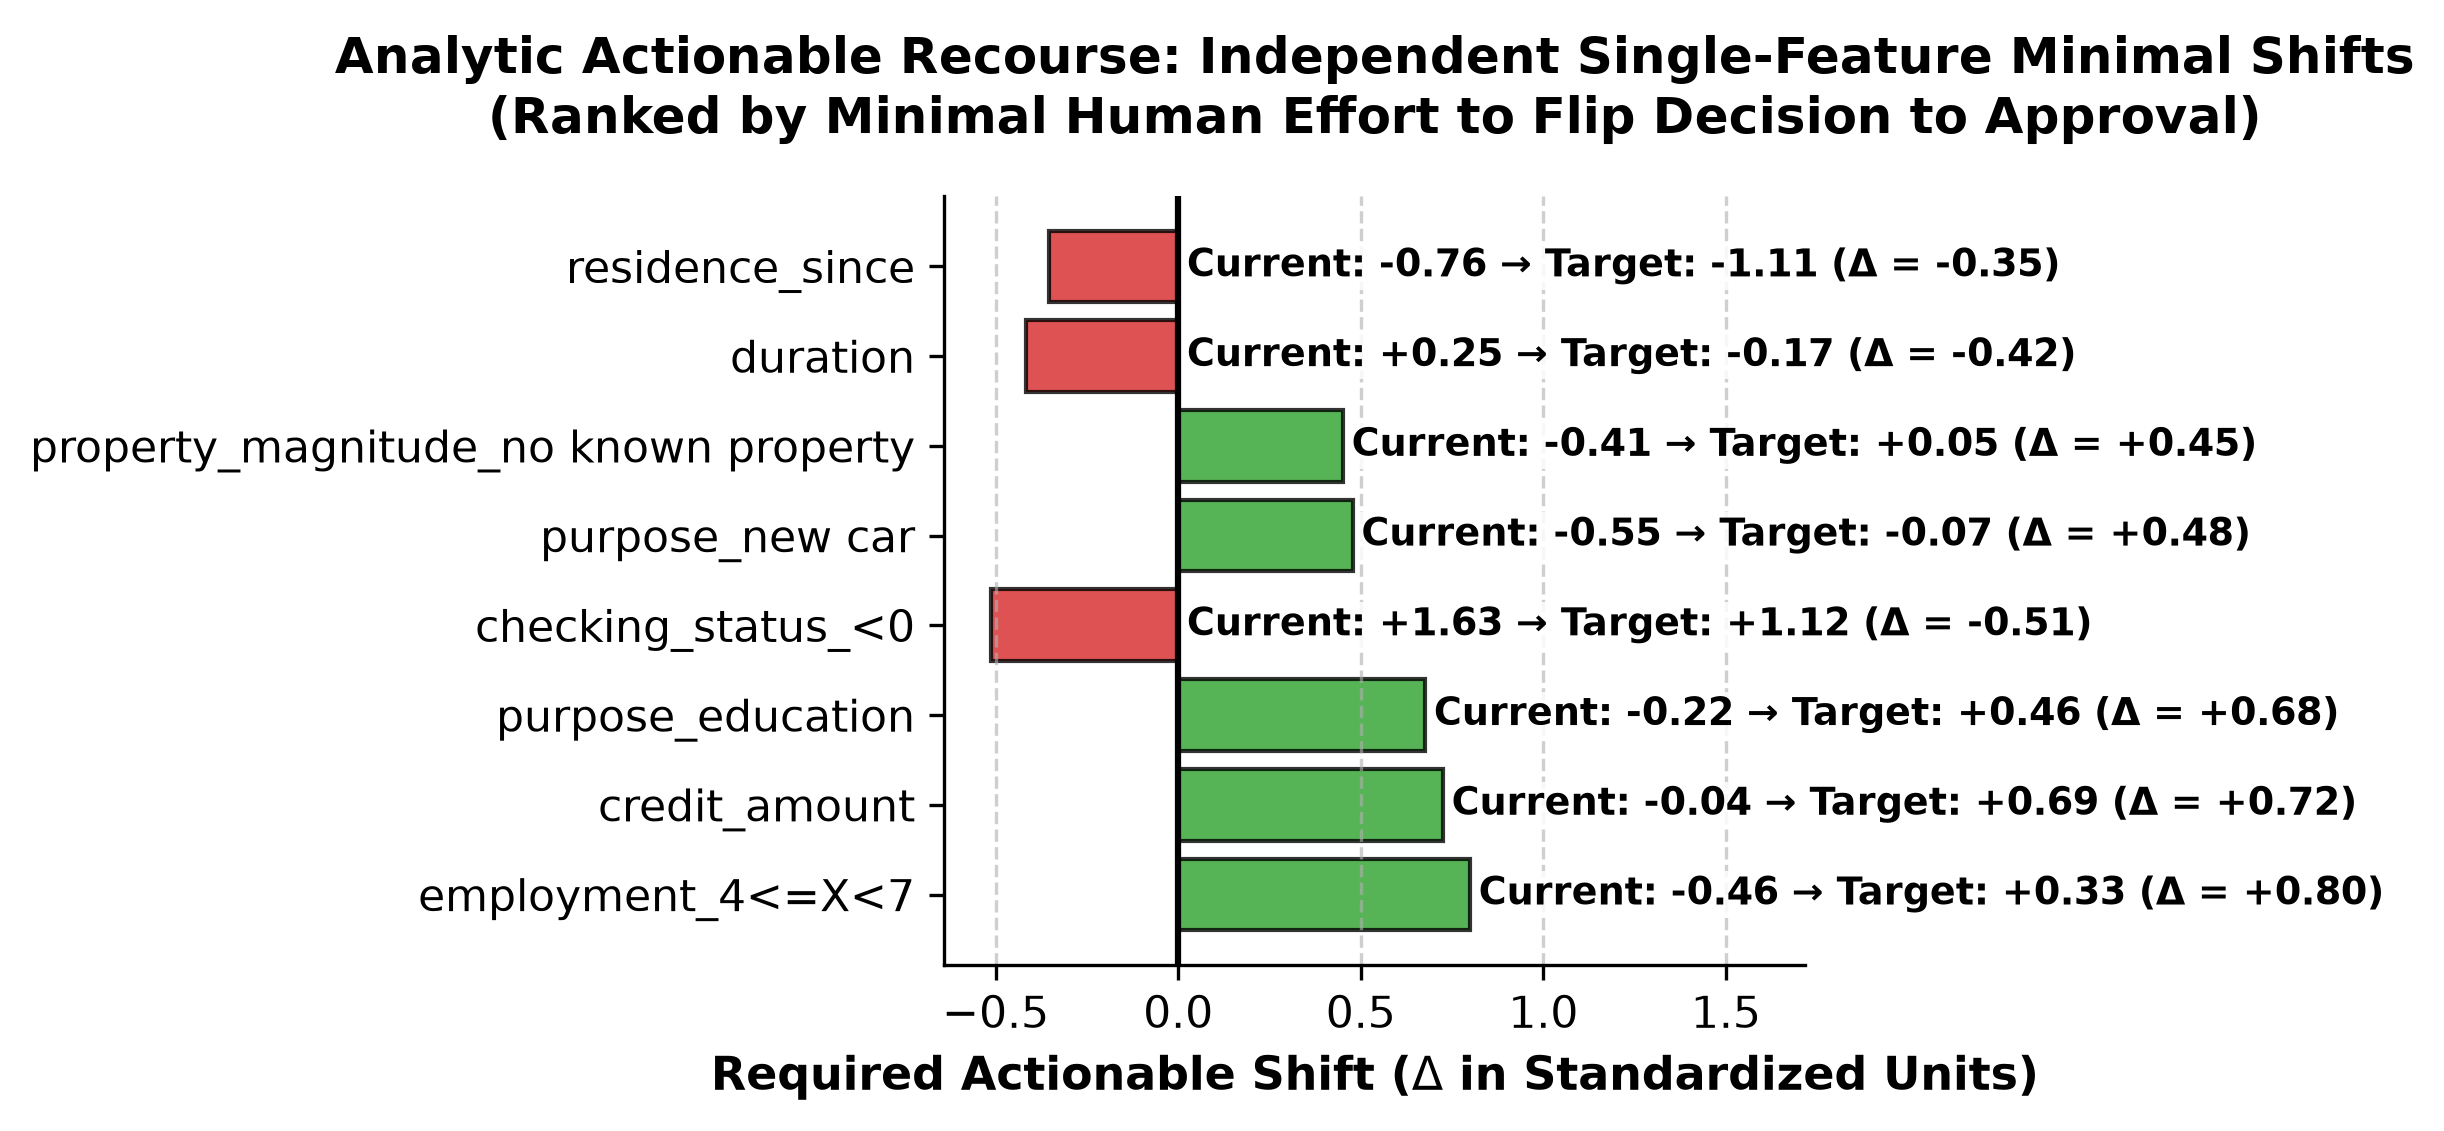


Figure 4 saved as PDF and PNG: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_actionable_recourse.pdf
Total valid single-feature actions found: 21
Top 5 lowest-effort actions:
  -> residence_since: Current=-0.76, Target=-1.11, Change=-0.35 (|Δ|=0.35)
  -> duration: Current=+0.25, Target=-0.17, Change=-0.42 (|Δ|=0.42)
  -> property_magnitude_no known property: Current=-0.41, Target=+0.05, Change=+0.45 (|Δ|=0.45)
  -> purpose_new car: Current=-0.55, Target=-0.07, Change=+0.48 (|Δ|=0.48)
  -> checking_status_<0: Current=+1.63, Target=+1.12, Change=-0.51 (|Δ|=0.51)


In [5]:
# ==============================================================================
# FIGURE 4: ANALYTIC ACTIONABLE RECOURSE
# ==============================================================================
fig_pdf_path = output_fig_dir / "fig_actionable_recourse.pdf"

recourse_actions = plot_exact_actionable_recourse(
    model=model_gc,
    single_record=selected_record,
    dataset_mins=dataset_mins,
    dataset_maxs=dataset_maxs,
    target_class=1,
    feature_names=feature_names_gc,
    top_k=8,
    figsize=(7.16, 3.9),
    title=(
        "Analytic Actionable Recourse: Independent Single-Feature Minimal Shifts\n"
        "(Ranked by Minimal Human Effort to Flip Decision to Approval)"
    ),
    xlabel=r"Required Actionable Shift ($\Delta$ in Standardized Units)",
    save_path=str(fig_pdf_path),
    show_plot=True,
    return_actions=True,
    lang="en",
    immutable_features=IMMUTABLE_FEATURES,
)

if not recourse_actions:
    fig, ax = plt.subplots(figsize=(7.16, 3.9))
    ax.axis("off")
    ax.text(
        0.5, 0.5,
        "No single-feature actionable recourse exists for the selected applicant.\n"
        "Re-run after retraining or inspect a different rejected sample.",
        ha="center", va="center", fontsize=11, color="#991B1B",
    )
    save_figure(fig, "fig_actionable_recourse")
    plt.show()
else:
    print(f"\nFigure 4 saved as PDF and PNG: {fig_pdf_path}")
    print(f"Total valid single-feature actions found: {len(recourse_actions)}")
    print("Top 5 lowest-effort actions:")
    for action in recourse_actions[:5]:
        print(
            f"  -> {action['feature']}: Current={action['orig']:+.2f}, "
            f"Target={action['target']:+.2f}, Change={action['diff']:+.2f} "
            f"(|Δ|={action['abs_diff']:.2f})"
        )

Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_feature_interaction.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_feature_interaction.png


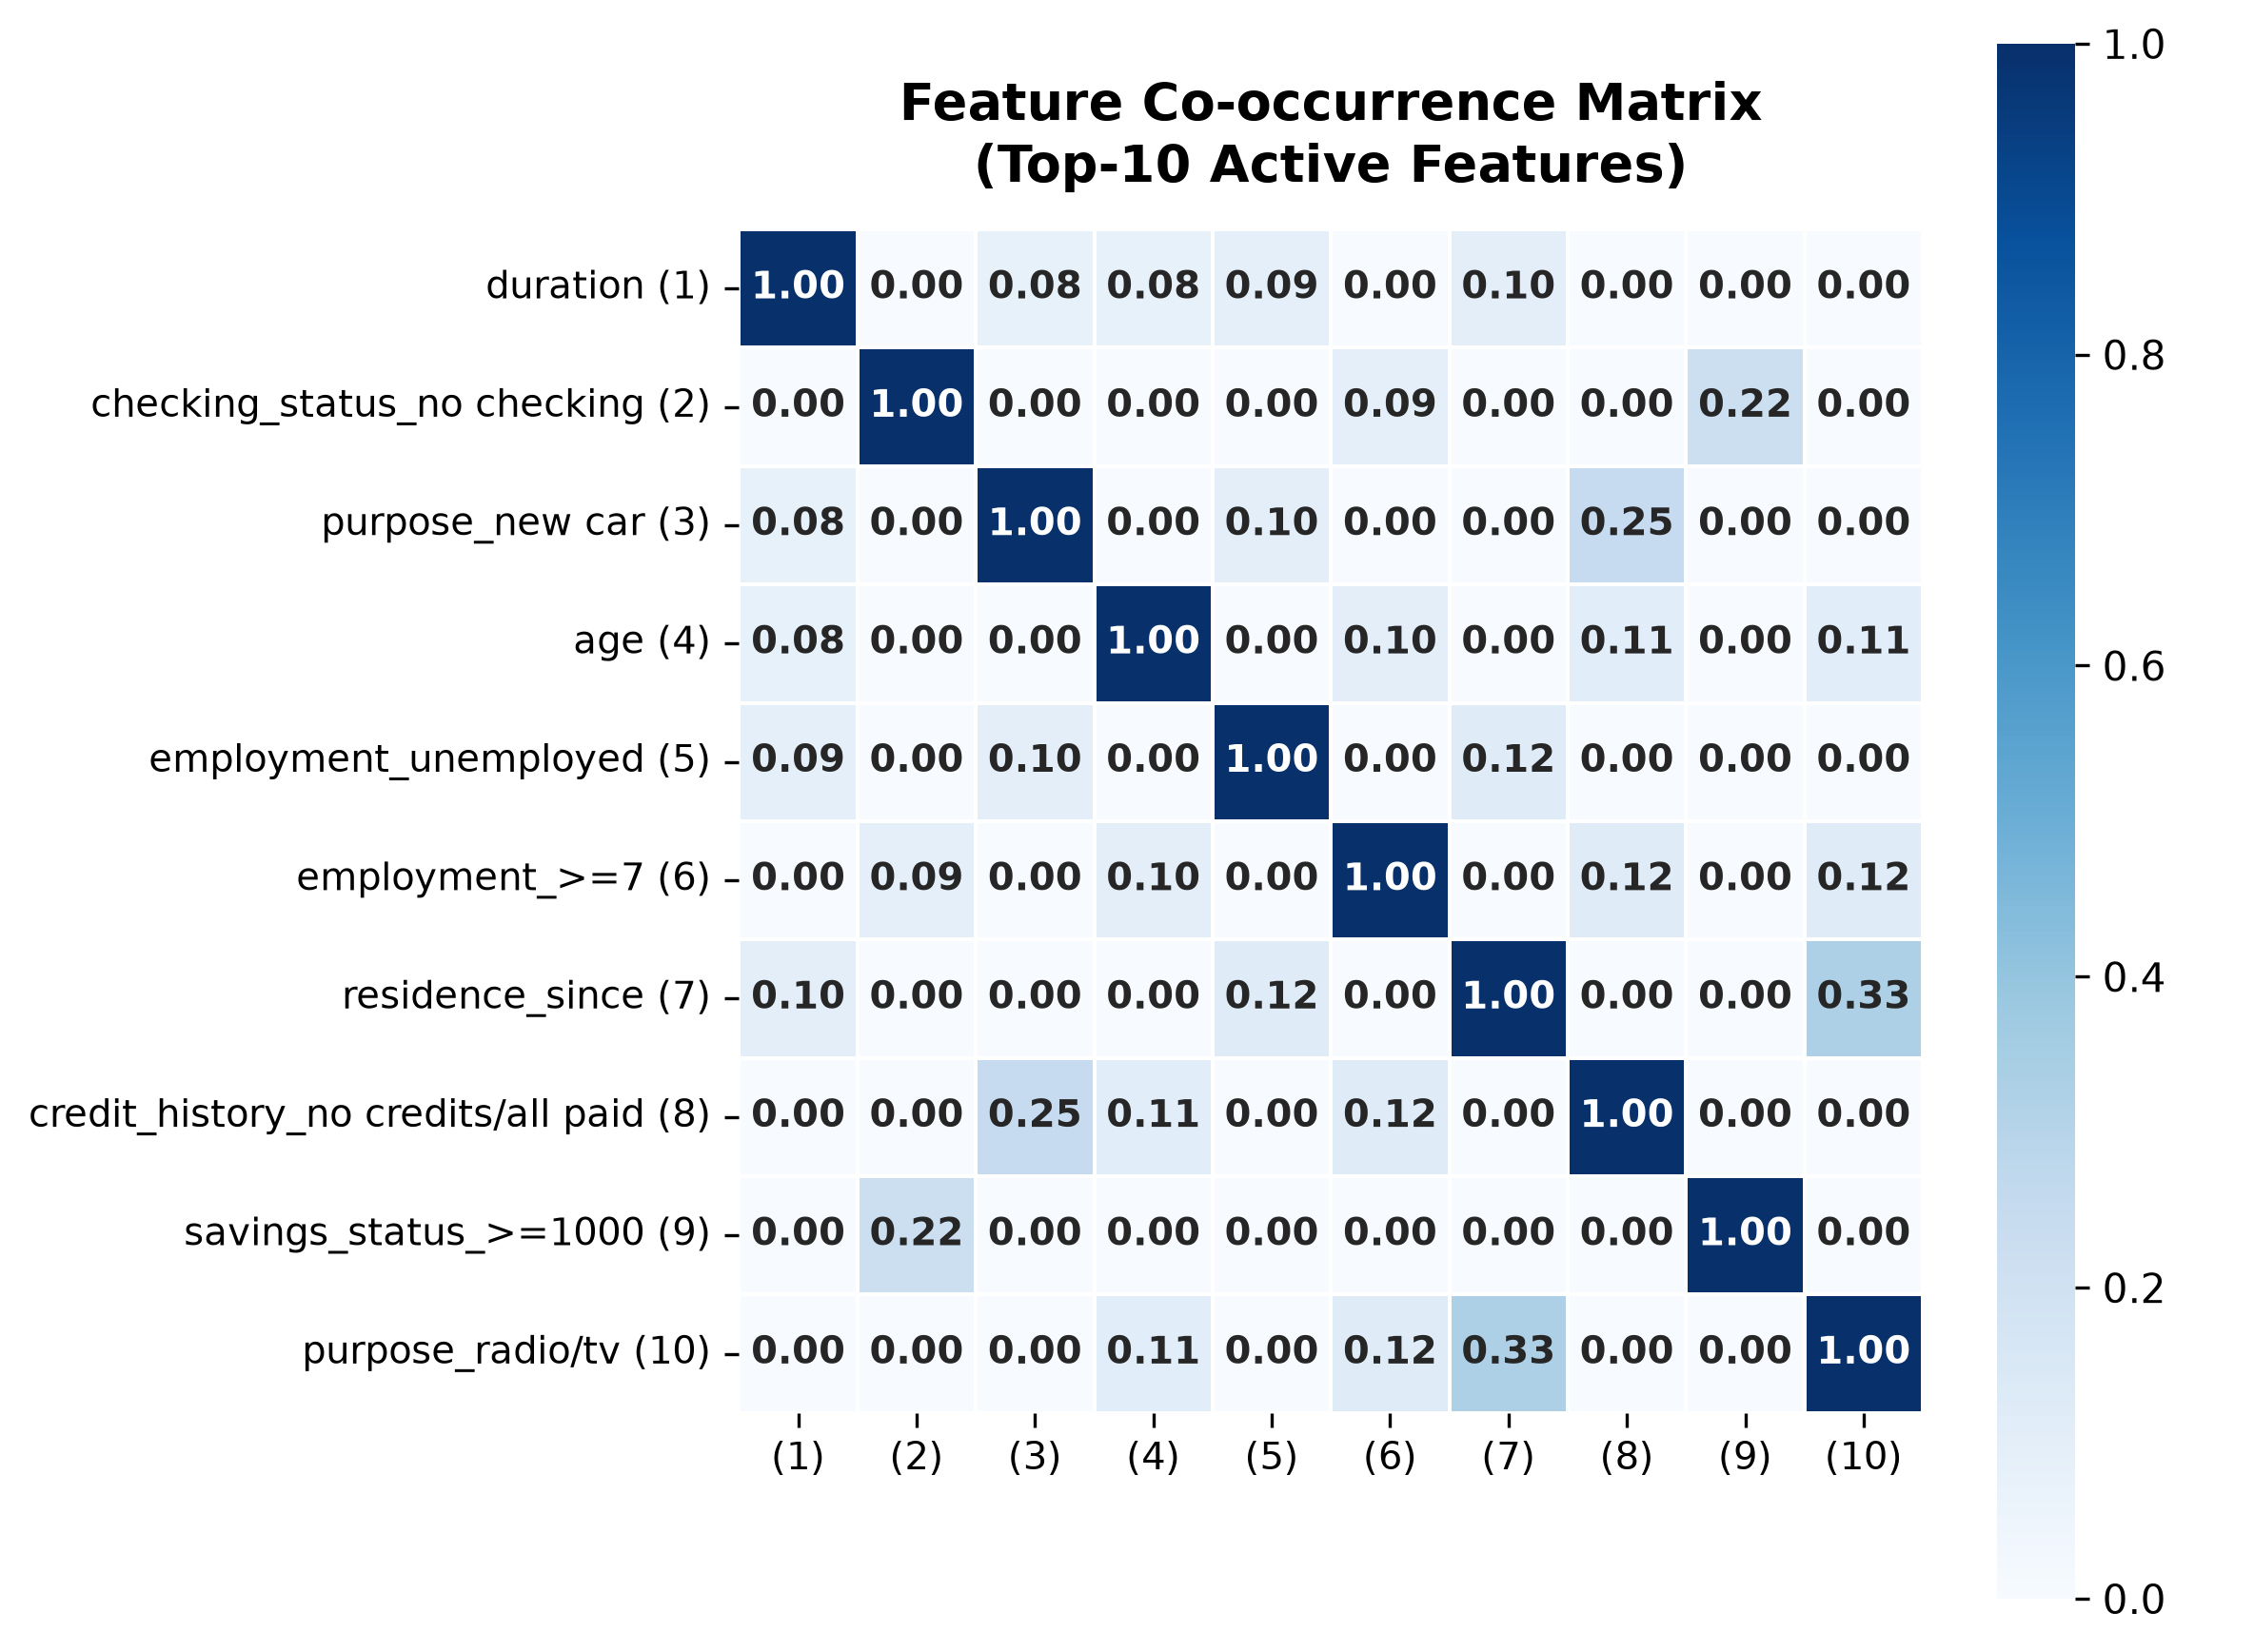

In [6]:
# ==============================================================================
# FIGURE 5: ARCHITECTURAL FEATURE CO-OCCURRENCE AND JACCARD SIMILARITY HEATMAP
# ==============================================================================
_, df_summary_gc, df_jaccard_gc = calculate_feature_rule_cooccurrence(
    model_gc, feature_names=feature_names_gc, threshold=1e-5
)

active_features = df_summary_gc[df_summary_gc["Total_Rule_Count"] > 0]
top_n = min(10, len(active_features))
if top_n == 0:
    top_features = feature_names_gc[: min(10, len(feature_names_gc))]
    top_n = len(top_features)
else:
    top_features = active_features.head(top_n)["Feature"].tolist()

jaccard_top = df_jaccard_gc.loc[top_features, top_features]

fig_w = max(6.0, 0.70 * top_n + 1.0)
fig_h = max(4.5, 0.55 * top_n + 1.0)
fig, ax = plt.subplots(figsize=(fig_w, fig_h))
sns.heatmap(
    jaccard_top,
    annot=top_n <= 12,
    fmt=".2f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Pairwise Jaccard Co-occurrence"},
    annot_kws={"fontsize": 9.5, "fontweight": "bold"},
    ax=ax,
)
ax.set_title(
    f"Feature Co-occurrence Matrix\n(Top-{top_n} Active Features)",
    fontweight="bold", fontsize=13, pad=12,
)
ax.set_xticklabels(
    [f"({i + 1})" for i in range(top_n)], rotation=0, ha="center", fontsize=9.5
)
ax.set_yticklabels(
    [f"{name} ({i + 1})" for i, name in enumerate(top_features)],
    rotation=0, fontsize=9.5,
)
cbar = ax.collections[0].colorbar
cbar.set_label(" ", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=10)
plt.tight_layout()
save_figure(fig, "fig_feature_interaction")
plt.show()

## Verification notes

* **Figure 1** uses only the **validation** accuracy in `training_history.json`; the test set does not leak into the pruning trajectory.
* **Figure 2** uses the dataset-specific quantization budget (`Λ_max`, `τ`) from `utils.experiments`; no single global tolerance is used.
* **Figures 3-5** compress the German Credit model at runtime; feature indices, rule counts, and the selected applicant are derived from the checkpoint.
* All figures are written as PDF + PNG under `paper/neurocomputing/figures/`.